# OpenBench Phase 3: IMDb Sentiment Baseline

## 1. Project overview

This notebook documents and demonstrates the existing Phase 3 experiment in OpenBench. It uses the IMDb Large Movie Review Dataset to classify reviews as negative (`0`) or positive (`1`).

The baseline combines **TF-IDF**, which turns words and short word sequences into numeric features, with **Logistic Regression**, a fast linear classifier. It provides a clear, reproducible reference point before later phases add neural models such as Text CNN, RNN, LSTM, and GRU. Neural models can learn richer representations, while this baseline is smaller, easier to inspect, and useful for measuring whether that extra complexity helps.

This notebook covers **Phase 3 only**. It does not implement preprocessing or the PyTorch data pipeline planned for Phase 4.

## 2. Environment and imports

Run this notebook with the project's existing `.venv` kernel. The code finds the project root by locating `pyproject.toml` and the `src/deeptext` package, so it does not depend on a machine-specific absolute path. No packages are installed here.

In [1]:
from importlib.metadata import version
from pathlib import Path
import json
import platform
import sys

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

candidate_directories = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    path
    for path in candidate_directories
    if (path / "pyproject.toml").is_file()
    and (path / "src" / "deeptext").is_dir()
)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from deeptext.data.dataset import load_imdb_split, split_training_data
from deeptext.experiments.baseline import run_baseline_experiment
from deeptext.models.baseline import (
    load_baseline_artifacts,
    predict_baseline,
    predict_baseline_probabilities,
)

DATASET_DIR = PROJECT_ROOT / "datasets" / "aclImdb"
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "baseline"
RANDOM_SEED = 42
VALIDATION_SIZE = 0.2

version_rows = [
    {"Library": "Python", "Version": platform.python_version()},
    {"Library": "scikit-learn", "Version": sklearn.__version__},
    {"Library": "pandas", "Version": pd.__version__},
    {"Library": "NumPy", "Version": np.__version__},
    {"Library": "Matplotlib", "Version": matplotlib.__version__},
    {"Library": "joblib", "Version": joblib.__version__},
]
environment_versions = pd.DataFrame(version_rows)
print(f"Project root: {PROJECT_ROOT}")
print(f"Notebook kernel: {sys.executable}")
environment_versions

Project root: C:\Users\thush\Documents\OpenBench
Notebook kernel: c:\Users\thush\Documents\OpenBench\.venv\Scripts\python.exe


,Library,Version
0,Python,3.15.2
1,scikit-learn,1.9.1
2,pandas,3.1.0
3,NumPy,2.5.4
4,Matplotlib,3.11.2
5,joblib,1.6.0


## 3. Dataset overview

The project loader reads the labeled **training** reviews. To keep the official test set untouched, its review text is never loaded in this notebook: the test count below comes only from counting `.txt` paths in the existing `neg` and `pos` folders. Unlabeled review files are counted from their folder and are not read or used by the model.

In [2]:
training_records = load_imdb_split(DATASET_DIR, "train")

def count_review_files(directory):
    return sum(1 for _ in directory.glob("*.txt"))

train_negative_count = int((training_records["label"] == 0).sum())
train_positive_count = int((training_records["label"] == 1).sum())
test_negative_count = count_review_files(DATASET_DIR / "test" / "neg")
test_positive_count = count_review_files(DATASET_DIR / "test" / "pos")
unlabeled_count = count_review_files(DATASET_DIR / "train" / "unsup")

dataset_overview = pd.DataFrame(
    [
        {
            "Partition": "Labeled training reviews",
            "Total": len(training_records),
            "Negative (0)": train_negative_count,
            "Positive (1)": train_positive_count,
            "Handling": "Loaded by the existing training loader",
        },
        {
            "Partition": "Official test reviews",
            "Total": test_negative_count + test_positive_count,
            "Negative (0)": test_negative_count,
            "Positive (1)": test_positive_count,
            "Handling": "File counts only; review text not loaded",
        },
        {
            "Partition": "Unlabeled training reviews",
            "Total": unlabeled_count,
            "Negative (0)": pd.NA,
            "Positive (1)": pd.NA,
            "Handling": "File count only; excluded from the experiment",
        },
    ]
)
dataset_overview

,Partition,Total,Negative (0),Positive (1),Handling
0,Labeled training reviews,25000,12500,12500,Loaded by the existing training loader
1,Official test reviews,25000,12500,12500,File counts only; review text not loaded
2,Unlabeled training reviews,50000,<NA>,<NA>,File count only; excluded from the experiment


## 4. Data splitting

The existing Phase 2 function makes a seeded, stratified split from the labeled training records. This baseline uses 80% for fitting and 20% for validation. The official test set is not passed to the split function.

`split_training_data` resets each returned DataFrame index. Therefore, the overlap check uses each review's stable `review_id` (the original relative file path), which is the row identity that matters across the two partitions.

In [3]:
training_partition, validation_partition = split_training_data(
    training_records,
    validation_size=VALIDATION_SIZE,
    seed=RANDOM_SEED,
)
repeated_training_partition, repeated_validation_partition = split_training_data(
    training_records,
    validation_size=VALIDATION_SIZE,
    seed=RANDOM_SEED,
)

training_review_ids = set(training_partition["review_id"])
validation_review_ids = set(validation_partition["review_id"])
split_is_reproducible = (
    training_partition["review_id"].tolist()
    == repeated_training_partition["review_id"].tolist()
    and validation_partition["review_id"].tolist()
    == repeated_validation_partition["review_id"].tolist()
)
review_ids_are_disjoint = training_review_ids.isdisjoint(validation_review_ids)

split_summary = pd.DataFrame(
    [
        {
            "Partition": "Training",
            "Samples": len(training_partition),
            "Negative (0)": int((training_partition["label"] == 0).sum()),
            "Positive (1)": int((training_partition["label"] == 1).sum()),
            "Fraction of original train": 1 - VALIDATION_SIZE,
        },
        {
            "Partition": "Validation",
            "Samples": len(validation_partition),
            "Negative (0)": int((validation_partition["label"] == 0).sum()),
            "Positive (1)": int((validation_partition["label"] == 1).sum()),
            "Fraction of original train": VALIDATION_SIZE,
        },
    ]
)
split_checks = pd.DataFrame(
    [
        {"Check": "Same seed reproduces both partitions", "Passed": split_is_reproducible},
        {"Check": "Training and validation review IDs are disjoint", "Passed": review_ids_are_disjoint},
        {"Check": "Random seed", "Passed": RANDOM_SEED},
        {"Check": "Validation fraction", "Passed": VALIDATION_SIZE},
    ]
)
split_summary, split_checks

(    Partition  Samples  Negative (0)  Positive (1)  Fraction of original train
 0    Training    20000         10000         10000                         0.8
 1  Validation     5000          2500          2500                         0.2,
                                              Check Passed
 0             Same seed reproduces both partitions   True
 1  Training and validation review IDs are disjoint   True
 2                                      Random seed     42
 3                              Validation fraction    0.2)

## 5. Baseline methodology

**TF-IDF** represents each review by word features. A word's score grows when it is frequent in a review and falls when the word is common across many reviews. A **unigram** is one word; a **bigram** is a pair of adjacent words, such as “not good”. Including bigrams lets this baseline represent some short word-order patterns.

Logistic Regression learns a linear decision boundary over these sparse features. Its `C` parameter controls regularization: smaller `C` applies stronger regularization, which penalizes large model weights more strongly. The vectorizer is fitted on training text only so validation vocabulary cannot influence the learned feature space. Validation scores compare configurations; the test set remains reserved for a later final evaluation.

```text
labeled training reviews ── seeded stratified split ──┬── fit TF-IDF + Logistic Regression
                                                       └── compare on validation
```

## 6. Existing baseline experiment

The experiment runner compares the same four configurations using the same seed, 80/20 training-validation split, and shared metrics. The first results below are loaded from the existing run's JSON metadata, so opening this notebook does **not** retrain the models.

In [4]:
metadata_paths = list(OUTPUT_ROOT.glob("*/metadata.json"))
if not metadata_paths:
    raise FileNotFoundError(
        f"No baseline experiment metadata was found under {OUTPUT_ROOT}."
    )

metadata_candidates = [
    (path, json.loads(path.read_text(encoding="utf-8")))
    for path in metadata_paths
]
metadata_path, experiment_metadata = max(
    metadata_candidates,
    key=lambda item: item[1].get("created_at_utc", ""),
)
selected_run_directory = metadata_path.parent

if experiment_metadata.get("official_test_evaluated") is not False:
    raise ValueError("The selected run metadata does not confirm test-set isolation.")
if experiment_metadata.get("vectorizer_fit_partition") != "training":
    raise ValueError("The selected run metadata does not confirm training-only TF-IDF fitting.")

print(f"Loaded existing run: {experiment_metadata['experiment_id']}")
print(f"Metadata: {metadata_path.relative_to(PROJECT_ROOT)}")
print("No model was retrained in this cell.")

Loaded existing run: imdb-baseline-20261030T110055.976336Z
Metadata: outputs\baseline\imdb-baseline-20261030T110055.976336Z\metadata.json
No model was retrained in this cell.


### Optional: rerun the validation experiment

Leave `RUN_EXPERIMENTS` set to `False` to use the existing results. Set it to `True` only when you intentionally want to repeat the four fits. The runner uses the existing split and evaluation APIs and writes a new timestamped artifact; it does not use the official test set.

In [5]:
RUN_EXPERIMENTS = False

if RUN_EXPERIMENTS:
    experiment_metadata = run_baseline_experiment(
        dataset_dir=DATASET_DIR,
        output_root=OUTPUT_ROOT,
        seed=RANDOM_SEED,
    )
    selected_run_directory = Path(experiment_metadata["artifact_directory"])
    metadata_path = selected_run_directory / "metadata.json"
    print(f"Created new run: {experiment_metadata['experiment_id']}")
    print(f"New metadata: {metadata_path}")
else:
    print("Using the existing recorded experiment; optional retraining is off.")

Using the existing recorded experiment; optional retraining is off.


## 7. Validation results comparison

This table is built from the active artifact's metadata. Timing and artifact size are recorded for the selected configuration; the other configurations show missing values for those selected-model-only measurements. Higher validation F1 is the primary selection criterion, with accuracy and the documented tie-breaks following it.

In [6]:
selected_settings = experiment_metadata["selected_settings"]
result_rows = []
for comparison in experiment_metadata["configuration_comparisons"]:
    settings = comparison["settings"]
    metrics = comparison["validation_metrics"]
    is_selected = (
        list(settings["ngram_range"]) == list(selected_settings["ngram_range"])
        and settings["c"] == selected_settings["c"]
    )
    ngram_label = (
        "Unigrams"
        if list(settings["ngram_range"]) == [1, 1]
        else "Unigrams + bigrams"
    )
    result_rows.append(
        {
            "TF-IDF configuration": ngram_label,
            "C": settings["c"],
            "Accuracy": metrics["accuracy"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1": metrics["f1"],
            "Training duration (s)": comparison["training_duration_seconds"],
            "Inference (ms/review)": (
                experiment_metadata["inference_latency"]["milliseconds_per_review"]
                if is_selected
                else np.nan
            ),
            "Artifact size (bytes)": (
                experiment_metadata["model_artifact_size_bytes"]
                if is_selected
                else pd.NA
            ),
            "Selected": is_selected,
        }
    )

results_dataframe = pd.DataFrame(result_rows).sort_values(
    ["F1", "Accuracy"], ascending=False, ignore_index=True
)
display_results = results_dataframe.copy()
for metric_name in ("Accuracy", "Precision", "Recall", "F1"):
    display_results[metric_name] = (100 * display_results[metric_name]).round(2)
display_results["Training duration (s)"] = display_results[
    "Training duration (s)"
].round(2)
display_results["Inference (ms/review)"] = display_results[
    "Inference (ms/review)"
].round(3)
display_results["Artifact size (bytes)"] = display_results[
    "Artifact size (bytes)"
].map(lambda size: "—" if pd.isna(size) else f"{int(size):,}")
display_results

,TF-IDF configuration,C,Accuracy,Precision,Recall,F1,Training duration (s),Inference (ms/review),Artifact size (bytes),Selected
0,Unigrams + bigrams,1.0,87.72,86.64,89.20,87.90,13.31,0.764,"22,676,878",True
1,Unigrams,1.0,87.46,86.60,88.64,87.61,2.64,NaN,—,False
2,Unigrams,0.1,83.62,81.85,86.40,84.06,2.37,NaN,—,False
3,Unigrams + bigrams,0.1,82.78,81.41,84.96,83.15,10.14,NaN,—,False


In [7]:
previously_reported = {
    ("Unigrams", 0.1): {"Accuracy": 0.8362, "F1": 0.840630472854641},
    ("Unigrams", 1.0): {"Accuracy": 0.8746, "F1": 0.8760624629373394},
    ("Unigrams + bigrams", 0.1): {"Accuracy": 0.8278, "F1": 0.8314738696418086},
    ("Unigrams + bigrams", 1.0): {"Accuracy": 0.8772, "F1": 0.8789909341742215},
}
discrepancies = []
for _, row in results_dataframe.iterrows():
    key = (row["TF-IDF configuration"], float(row["C"]))
    reference = previously_reported.get(key)
    if reference is None:
        discrepancies.append({"Configuration": key, "Difference": "No prior reference"})
        continue
    for metric_name, reference_value in reference.items():
        current_value = float(row[metric_name])
        if not np.isclose(current_value, reference_value, atol=1e-12):
            discrepancies.append(
                {
                    "Configuration": f"{key[0]}, C={key[1]}",
                    "Difference": (
                        f"{metric_name}: current metadata {current_value:.6f}; "
                        f"previously reported {reference_value:.6f}"
                    ),
                }
            )
if discrepancies:
    discrepancy_table = pd.DataFrame(discrepancies)
    print("The current artifact metadata differs from the prior report:")
    discrepancy_table
else:
    print("Current artifact accuracy and F1 match the previously reported results.")

Current artifact accuracy and F1 match the previously reported results.


## 8. Validation visualizations

These charts compare validation results only. The confusion matrix uses rows for actual labels and columns for predicted labels, ordered negative (`0`) then positive (`1`).

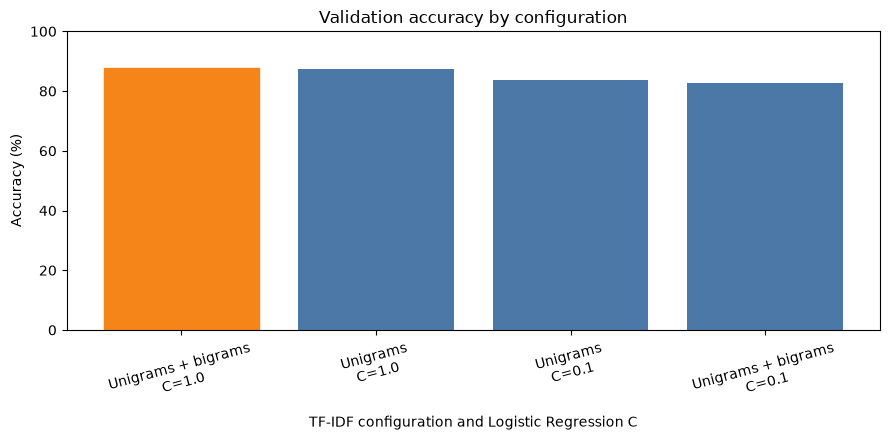

In [8]:
chart_labels = [
    f"{row['TF-IDF configuration']}\nC={row['C']}"
    for _, row in results_dataframe.iterrows()
]
selected_index = results_dataframe.index[results_dataframe["Selected"]][0]
selected_metrics = experiment_metadata["validation_metrics"]
selected_confusion = np.asarray(selected_metrics["confusion_matrix"])

figure, axis = plt.subplots(figsize=(9, 4.5))
bars = axis.bar(chart_labels, 100 * results_dataframe["Accuracy"], color="#4C78A8")
bars[selected_index].set_color("#F58518")
axis.set_title("Validation accuracy by configuration")
axis.set_ylabel("Accuracy (%)")
axis.set_xlabel("TF-IDF configuration and Logistic Regression C")
axis.set_ylim(0, 100)
axis.tick_params(axis="x", labelrotation=15)
figure.tight_layout()
plt.show()


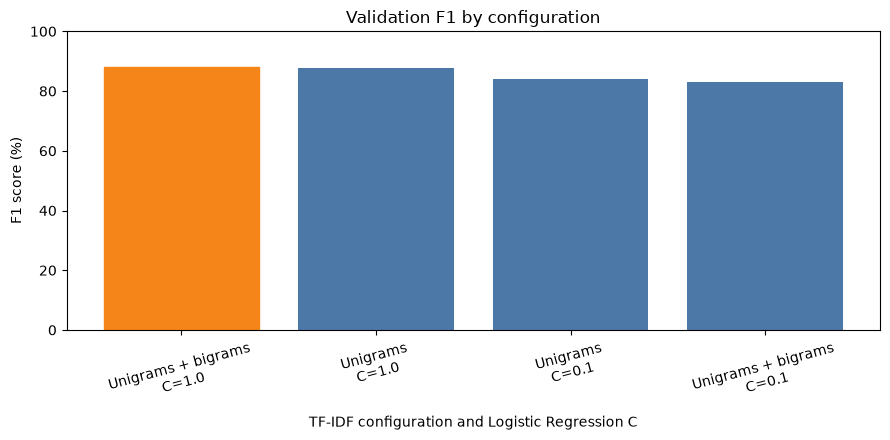

In [9]:
figure, axis = plt.subplots(figsize=(9, 4.5))
bars = axis.bar(chart_labels, 100 * results_dataframe["F1"], color="#4C78A8")
bars[selected_index].set_color("#F58518")
axis.set_title("Validation F1 by configuration")
axis.set_ylabel("F1 score (%)")
axis.set_xlabel("TF-IDF configuration and Logistic Regression C")
axis.set_ylim(0, 100)
axis.tick_params(axis="x", labelrotation=15)
figure.tight_layout()
plt.show()

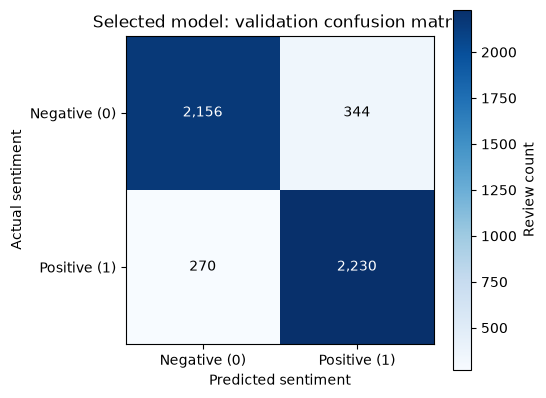

In [10]:
figure, axis = plt.subplots(figsize=(5.5, 4.5))
image = axis.imshow(selected_confusion, cmap="Blues")
axis.set_title("Selected model: validation confusion matrix")
axis.set_xlabel("Predicted sentiment")
axis.set_ylabel("Actual sentiment")
axis.set_xticks([0, 1], labels=["Negative (0)", "Positive (1)"])
axis.set_yticks([0, 1], labels=["Negative (0)", "Positive (1)"])
threshold = selected_confusion.max() / 2
for row_index in range(2):
    for column_index in range(2):
        axis.text(
            column_index,
            row_index,
            f"{selected_confusion[row_index, column_index]:,}",
            ha="center",
            va="center",
            color="white" if selected_confusion[row_index, column_index] > threshold else "black",
        )
figure.colorbar(image, ax=axis, label="Review count")
figure.tight_layout()
plt.show()

## 9. Inspect the selected model

The following examples demonstrate the prediction API, not a guarantee of correctness. They are hand-written short examples and are not used to tune the model.

In [11]:
selected_model, loaded_metadata = load_baseline_artifacts(selected_run_directory)
example_reviews = [
    "A warm, funny story with excellent acting and a satisfying ending.",
    "A dull and confusing film with wooden acting and a terrible ending.",
    "I loved the performances and would happily watch it again.",
    "The plot was weak, the pacing was slow, and I disliked it.",
]
example_predictions = predict_baseline(selected_model, example_reviews)
example_probabilities = predict_baseline_probabilities(
    selected_model, example_reviews
)
example_table = pd.DataFrame(
    {
        "Example review": example_reviews,
        "Predicted sentiment": [
            "Positive" if prediction == 1 else "Negative"
            for prediction in example_predictions
        ],
        "P(negative)": example_probabilities[:, 0].round(4),
        "P(positive)": example_probabilities[:, 1].round(4),
        "Predicted-class probability": [
            example_probabilities[index, prediction]
            for index, prediction in enumerate(example_predictions)
        ],
    }
)
selected_model_summary = pd.DataFrame(
    [
        {"Item": "Selected settings", "Value": str(loaded_metadata["selected_settings"])},
        {"Item": "Validation metrics", "Value": str(loaded_metadata["validation_metrics"])},
        {"Item": "Model file", "Value": loaded_metadata["model_artifact"]},
    ]
)
selected_model_summary, example_table

(                 Item                                              Value
 0   Selected settings  {'c': 1.0, 'max_iter': 1000, 'ngram_range': [1...
 1  Validation metrics  {'accuracy': 0.8772, 'confusion_matrix': [[215...
 2          Model file                                    baseline.joblib,
                                       Example review Predicted sentiment  \
 0  A warm, funny story with excellent acting and ...            Positive   
 1  A dull and confusing film with wooden acting a...            Negative   
 2  I loved the performances and would happily wat...            Positive   
 3  The plot was weak, the pacing was slow, and I ...            Negative   
 
    P(negative)  P(positive)  Predicted-class probability  
 0       0.2126       0.7874                     0.787377  
 1       0.8589       0.1411                     0.858856  
 2       0.0723       0.9277                     0.927701  
 3       0.8108       0.1892                     0.810801  )

## 10. Verify artifact reload

The experiment runner compared the fitted model with the saved-and-reloaded model when the artifact was created. To avoid fitting another full baseline just for this notebook, the next cell verifies that the recorded check succeeded and independently loads the artifact twice to confirm stable labels and probabilities on the same sample.

In [12]:
first_reload, _ = load_baseline_artifacts(selected_run_directory)
second_reload, _ = load_baseline_artifacts(selected_run_directory)
verification_reviews = example_reviews
first_labels = predict_baseline(first_reload, verification_reviews)
second_labels = predict_baseline(second_reload, verification_reviews)
first_probabilities = predict_baseline_probabilities(
    first_reload, verification_reviews
)
second_probabilities = predict_baseline_probabilities(
    second_reload, verification_reviews
)
reload_verification = pd.DataFrame(
    [
        {
            "Check": "Recorded fit-to-reload predictions matched",
            "Passed": loaded_metadata["artifact_reload_predictions_equivalent"],
        },
        {
            "Check": "Repeated artifact loads produce the same labels",
            "Passed": first_labels == second_labels,
        },
        {
            "Check": "Repeated artifact loads produce the same probabilities",
            "Passed": bool(np.allclose(first_probabilities, second_probabilities)),
        },
    ]
)
reload_verification

,Check,Passed
0,Recorded fit-to-reload predictions matched,True
1,Repeated artifact loads produce the same labels,True
2,Repeated artifact loads produce the same proba...,True


## 11. Limitations and data quality

- The dataset audit found **418 duplicate labeled reviews**. They remain unchanged under the documented policy.
- In the seeded training-validation split, **26 unique exact review texts** are shared across partitions, matching **28 validation rows**. This overlap may make validation performance optimistic; the notebook does not remove duplicates or inspect the test set for overlap.
- The official test set has not been evaluated. Its counts above are directory file counts only; review text was not loaded.
- TF-IDF and Logistic Regression provide a useful, interpretable traditional baseline, but they do not understand context or meaning like a person.
- The selected configuration is best among these four tested settings on this validation split. It is not necessarily the best possible model or configuration.
- Inference timing is an approximate single-review measurement over 100 validation examples and can vary by machine and runtime conditions.

## 12. Conclusion

The results table above identifies the best tested configuration and its measured validation metrics from the currently selected artifact metadata. This experiment shows how a conventional text pipeline can establish a reproducible reference before comparing more complex approaches.

Later work can compare the same task with neural models using a shared evaluation protocol. **Phase 4 preprocessing and the PyTorch data pipeline are not implemented by this notebook.** No neural or GPU training is performed here, and the official test set remains reserved for final evaluation.

In [13]:
conclusion = pd.DataFrame(
    [
        {"Measure": "Selected TF-IDF", "Result": "Unigrams + bigrams"},
        {"Measure": "Logistic Regression C", "Result": selected_settings["c"]},
        {"Measure": "Validation accuracy", "Result": f"{100 * selected_metrics['accuracy']:.2f}%"},
        {"Measure": "Validation precision", "Result": f"{100 * selected_metrics['precision']:.2f}%"},
        {"Measure": "Validation recall", "Result": f"{100 * selected_metrics['recall']:.2f}%"},
        {"Measure": "Validation F1", "Result": f"{100 * selected_metrics['f1']:.2f}%"},
        {"Measure": "Official test evaluated", "Result": "No"},
        {"Measure": "Phase 4 implemented", "Result": "No"},
    ]
)
conclusion

,Measure,Result
0,Selected TF-IDF,Unigrams + bigrams
1,Logistic Regression C,1.0
2,Validation accuracy,87.72%
3,Validation precision,86.64%
4,Validation recall,89.20%
5,Validation F1,87.90%
6,Official test evaluated,No
7,Phase 4 implemented,No
